# EE5130 · Reinforcement Learning in Autonomous mobile robots and Deep Reinforcement learning


| Part | Method | Needs a Model of the World? | Implemented With |
|---|---|---|---|
| 1 | Grid-world MDP for robot navigation using a Gymnasium-style `reset/step` API | Not required to interact with the environment | NumPy |
| 2 | **Value Iteration and Policy Iteration** (dynamic programming) | Yes — requires transition probabilities and rewards | NumPy |
| 3 | **Q-Learning** (tabular, ε-greedy) | No — learns through interaction with the environment | NumPy |
| 4 | **Deep Q-Network (DQN)** using a neural Q-function, replay buffer, and target network | No — learns through interaction with the environment | PyTorch |
| 5 | **Stable-Baselines3 DQN** applied to the same environment | No — learns through interaction with the environment | `gymnasium`, `stable_baselines3` |
| 6 | Evaluation using cumulative reward, **success rate, path length, convergence, and stability across random seeds** | Depends on the evaluation method | NumPy, Matplotlib |

## Bellman Optimality Equation

For the optimal state-value function:

$$
V^*(s) = \max_a \sum_{s'} P(s' \mid s,a)
\left[R(s,a,s') + \gamma V^*(s')\right]
$$

**Where:**

- $V^*(s)$: Optimal expected return from state $s$.
- $s$: Current state.
- $a$: Action selected by the agent.
- $s'$: Next state.
- $P(s' \mid s,a)$: Probability of transitioning to state $s'$ after taking action $a$ in state $s$.
- $R(s,a,s')$: Immediate reward for the transition.
- $\gamma$: Discount factor, where $0 \leq \gamma < 1$.

**Learning objective:** Understand the differences between model-based dynamic programming and model-free reinforcement learning, implement classical and deep RL algorithms, and evaluate their performance on a common robot navigation task.

In [ ]:
import sys, subprocess, importlib, time, warnings; warnings.filterwarnings("ignore")

def ensure(pkg, module=None):
    try: importlib.import_module(module or pkg)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

ensure("gymnasium"); ensure("stable-baselines3", "stable_baselines3")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn, random

from collections import deque

from pathlib import Path

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

DATA = Path("data"); DATA.mkdir(exist_ok=True)

## Part 1 — The Environment

### Grid-World Robot Navigation

The environment consists of a **6 × 6 grid world** in which a robot must navigate from the starting position to the goal while avoiding obstacles.

- **Start (S):** $(0,0)$
- **Goal (G):** $(5,5)$
- **Obstacles:** Blocked cells that the robot must avoid.
- **Action space:** Four discrete actions: Up ($\uparrow$), Right ($\rightarrow$), Down ($\downarrow$), and Left ($\leftarrow$).
- **Stochastic transitions:** With probability `slip = 0.1`, the robot executes a randomly selected action instead of the intended action.
- **Maximum episode length:** 50 steps.

### Reward Structure

| Event | Reward | Effect |
|---|---:|---|
| Reaching the goal | +10 | Episode terminates successfully |
| Each movement step | −1 | Encourages shorter paths |
| Bumping into an obstacle | −10 | Robot remains in its current cell; episode continues |

### Reward-Design Lesson

**Collision penalties should be designed carefully.**

If a collision terminates the episode, the robot might learn an undesirable policy in which it deliberately crashes to avoid accumulating step penalties. For example, an immediate collision penalty of −11 could be preferable to wandering for 50 steps and accumulating a reward of −50.

To avoid this behavior, obstacle collisions are **non-terminal constraint violations**: the robot receives a −10 penalty but remains in the same cell and continues the episode.

This design encourages the agent to reach the goal efficiently while learning to avoid collisions.

**Objective:** Model a stochastic robot navigation problem that demonstrates how transition uncertainty, reward design, and safety constraints affect reinforcement learning.

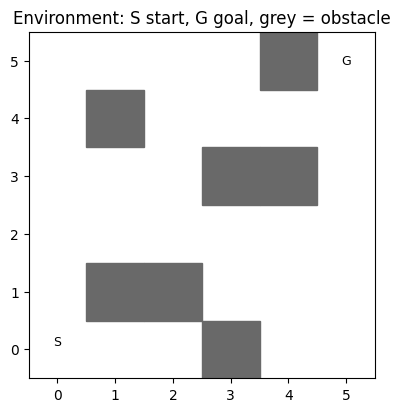

In [ ]:
ARROWS = ["↑", "→", "↓", "←"]; MOVES = [(0, 1), (1, 0), (0, -1), (-1, 0)]

class GridRobot:
    def __init__(s, n=6, obstacles=((1, 1), (2, 1), (3, 3), (4, 3), (1, 4), (3, 0), (4, 5)), start=(0, 0), goal=(5, 5), slip=0.1, max_steps=50, seed=0):
        s.n, s.obs, s.start, s.goal, s.slip, s.max_steps = n, set(obstacles), start, goal, slip, max_steps
        s.rng = np.random.default_rng(seed); s.nS, s.nA = n * n, 4

    def idx(s, p): return p[1] * s.n + p[0]
    def pos(s, i): return (i % s.n, i // s.n)

    def _move(s, p, a):
        q = (min(max(p[0] + MOVES[a][0], 0), s.n - 1), min(max(p[1] + MOVES[a][1], 0), s.n - 1))
        if q in s.obs: return p, -10, False
        if q == s.goal: return q, 10, True
        return q, -1, False

    def transitions(s, i, a):
        out = {}
        for b in range(4):
            p = (1 - s.slip) + s.slip / 4 if b == a else s.slip / 4
            q, r, d = s._move(s.pos(i), b); key = (s.idx(q), r, d)
            out[key] = out.get(key, 0) + p
        return [(p, j, r, d) for (j, r, d), p in out.items()]

    def features(s, p):
        blocked = [float((p[0] + dx, p[1] + dy) in s.obs or not (0 <= p[0] + dx < s.n and 0 <= p[1] + dy < s.n)) for dx, dy in MOVES]
        return np.array([p[0] / (s.n - 1), p[1] / (s.n - 1), *blocked], np.float32)

    def reset(s):
        s.p, s.t, s.collisions = s.start, 0, 0; return s.idx(s.p)

    def step(s, a):
        if s.rng.random() < s.slip: a = s.rng.integers(4)
        s.p, r, done = s._move(s.p, a); s.t += 1; s.collisions += (r == -10)
        return s.idx(s.p), r, done or s.t >= s.max_steps, s.p == s.goal

env = GridRobot()

def draw(ax, V=None, policy=None, title="", path=None):
    n = env.n; M = np.full((n, n), np.nan)
    if V is not None:
        for i in range(env.nS): M[env.pos(i)[1], env.pos(i)[0]] = V[i]
    ax.imshow(M, origin="lower", cmap="RdYlGn")
    for (x, y) in env.obs: ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, color="dimgray"))
    for i in range(env.nS):
        x, y = env.pos(i)
        if (x, y) in env.obs: continue
        txt = "G" if (x, y) == env.goal else ("S\n" if (x, y) == env.start else "") + (ARROWS[policy[i]] if policy is not None else "")
        if V is not None and (x, y) != env.goal: txt += f"\n{V[i]:.1f}"
        ax.text(x, y, txt, ha="center", va="center", fontsize=9)
    if path: ax.plot(*zip(*path), "b-", lw=2.5, alpha=.6)
    ax.set_xticks(range(n)); ax.set_yticks(range(n)); ax.set_title(title)

fig, ax = plt.subplots(figsize=(4.5, 4.5)); draw(ax, title="Environment: S start, G goal, grey = obstacle"); plt.show()


## Part 2 — Dynamic Programming (Known Model)

### 2.1 Value Iteration

**Value Iteration** is a model-based Dynamic Programming algorithm that computes the optimal state-value function by repeatedly applying the Bellman Optimality Equation. It uses the known transition probability model \(P(s'|s,a)\) and reward function \(R(s,a,s')\) to determine the maximum expected cumulative reward for each state.

**Bellman Optimality Equation:**

$$
V^*(s)=\max_{a\in A}
\sum_{s'\in S}P(s'|s,a)
\left[
R(s,a,s')+\gamma V^*(s')
\right]
$$

**Iterative Value Update:**

Starting with an initial state-value function \(V_0(s)=0\), the algorithm repeatedly updates the value of each non-terminal state:

$$
\boxed{
V_{k+1}(s)=
\max_{a\in A}
\sum_{s'\in S}P(s'|s,a)
\left[
R(s,a,s')+\gamma V_k(s')
\right]
}
$$

For terminal states, the value is maintained at zero:

$$
V_{k+1}(s)=0,\qquad s\in\mathcal{T}
$$

where \(\mathcal{T}\) represents the set of terminal states.

**Convergence Criterion:**

The algorithm measures the maximum change in state values between consecutive iterations:

$$
\Delta_k=\max_{s\in S}
\left|V_{k+1}(s)-V_k(s)\right|
$$

The iteration process terminates when:

$$
\boxed{\Delta_k<\theta}
$$

where \(\theta\) is the predefined convergence tolerance.

**Optimal Policy Extraction:**

After convergence, the optimal greedy policy is obtained by selecting the action with the highest expected return:

$$
\boxed{
\pi^*(s)=\arg\max_{a\in A}
\sum_{s'\in S}P(s'|s,a)
\left[
R(s,a,s')+\gamma V^*(s')
\right]
}
$$

**Learning Objective:** Determine the optimal state-value function and corresponding robot navigation policy by repeatedly evaluating all available actions using the known stochastic transition and reward models until convergence.


In [ ]:
def value_iteration(env, gamma=0.95, tol=1e-6):
    V = np.zeros(env.nS); deltas = []

    terminal = {env.idx(o) for o in env.obs} | {env.idx(env.goal)}

    while True:
        Vn = V.copy()
        for i in range(env.nS):
            if i in terminal: continue
            Vn[i] = max(sum(p * (r + gamma * V[j] * (not d)) for p, j, r, d in env.transitions(i, a)) for a in range(4))

        deltas.append(np.abs(Vn - V).max()); V = Vn

        if deltas[-1] < tol: break

    pi = np.array([np.argmax([sum(p * (r + gamma * V[j] * (not d)) for p, j, r, d in env.transitions(i, a)) for a in range(4)]) for i in range(env.nS)])
    return V, pi, deltas

t0 = time.time(); V_vi, pi_vi, deltas = value_iteration(env); t_vi = time.time() - t0

print(f"Value iteration converged in {len(deltas)} sweeps ({t_vi*1e3:.0f} ms)")

Value iteration converged in 30 sweeps (31 ms)



### 2.2 Policy Iteration (Policy Evaluation ↔ Policy Improvement)

**Policy Iteration** is a model-based Dynamic Programming algorithm that determines the optimal policy through two successive stages: **Policy Evaluation** and **Policy Improvement**. It uses the known transition probability model \(P(s'|s,a)\) and reward function \(R(s,a,s')\) to iteratively evaluate and improve the robot's navigation policy until policy convergence.

**1. Policy Initialization:**

An initial policy is assigned to every state:

$$
\pi_0(s)\in A,\qquad \forall s\in S
$$

The initial state-value function is initialized as:

$$
V_0(s)=0,\qquad \forall s\in S
$$

**2. Policy Evaluation:**

For a given policy \(\pi\), the state-value function is estimated by repeatedly applying the Bellman Expectation Equation:

$$
\boxed{
V_{k+1}^{\pi}(s)=
\sum_{s'\in S}P(s'|s,\pi(s))
\left[
R(s,\pi(s),s')+
\gamma V_k^{\pi}(s')I(s'\notin\mathcal{T})
\right]
}
$$

where \(\mathcal{T}\) represents the set of terminal states. The evaluation process is repeated until the state-value estimates are sufficiently accurate.

For terminal states:

$$
V^{\pi}(s)=0,\qquad s\in\mathcal{T}
$$

**3. Policy Improvement:**

After evaluating the current policy, the algorithm calculates the expected return associated with every available action:

$$
Q^{\pi}(s,a)=
\sum_{s'\in S}P(s'|s,a)
\left[
R(s,a,s')+
\gamma V^{\pi}(s')I(s'\notin\mathcal{T})
\right]
$$

The policy is then improved by selecting the action with the maximum expected return:

$$
\boxed{
\pi_{\mathrm{new}}(s)=
\arg\max_{a\in A}Q^{\pi}(s,a)
}
$$

**4. Policy Convergence:**

The updated policy is compared with the previous policy:

$$
\pi_{\mathrm{new}}(s)=\pi_{\mathrm{old}}(s),
\qquad \forall s\notin\mathcal{T}
$$

If the policy remains unchanged for all non-terminal states, the algorithm terminates. Otherwise, policy evaluation and policy improvement are repeated using the updated policy.

**5. Optimal Policy:**

Upon convergence, the algorithm returns the optimal policy and its corresponding state-value function:

$$
\boxed{
\pi^*(s)=
\arg\max_{a\in A}
\sum_{s'\in S}P(s'|s,a)
\left[
R(s,a,s')+\gamma V^{\pi^*}(s')
\right]
}
$$

**Learning Objective:** Determine the optimal robot navigation policy by repeatedly evaluating the expected returns of the current policy and improving action selections using the known stochastic transition and reward models until policy stability is achieved.


Policy iteration: 5 improvement steps | same policy as value iteration on free cells: True


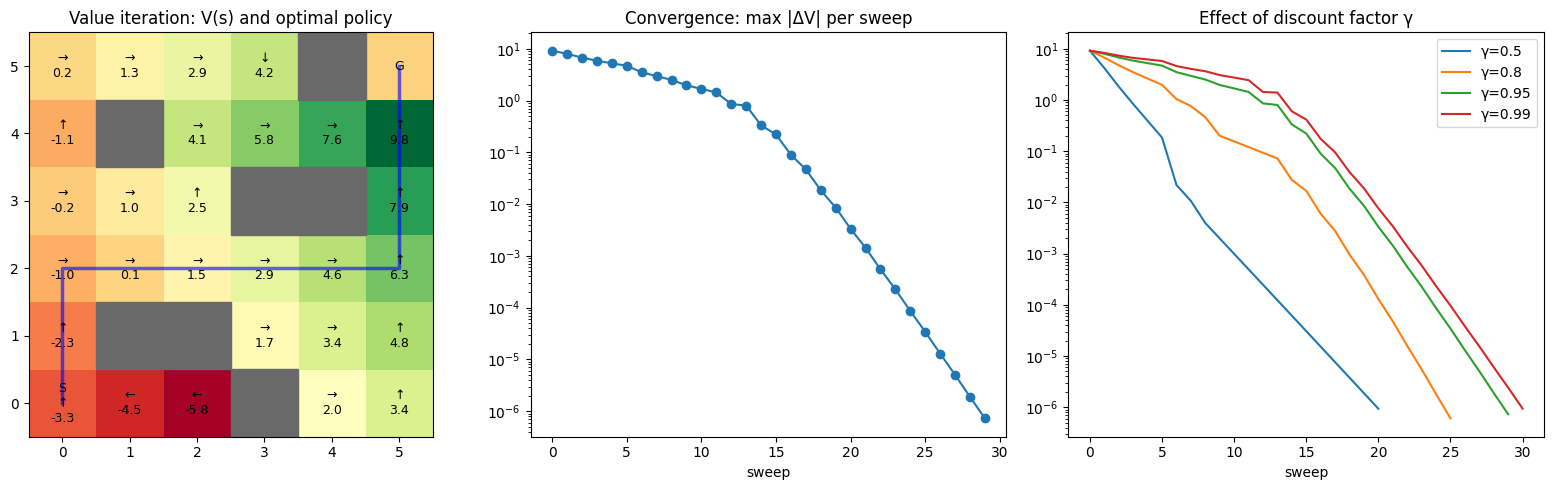

In [ ]:
def policy_iteration(env, gamma=0.95):
    pi = np.zeros(env.nS, int); terminal = {env.idx(o) for o in env.obs} | {env.idx(env.goal)}; it = 0
    while True:
        it += 1; V = np.zeros(env.nS)

        for _ in range(500):
            V = np.array([0 if i in terminal else sum(p * (r + gamma * V[j] * (not d)) for p, j, r, d in env.transitions(i, pi[i])) for i in range(env.nS)])

        new = np.array([np.argmax([sum(p * (r + gamma * V[j] * (not d)) for p, j, r, d in env.transitions(i, a)) for a in range(4)]) for i in range(env.nS)])

        if (new == pi).all(): return V, pi, it
        pi = new

V_pi, pi_pi, n_it = policy_iteration(env)

print(f"Policy iteration: {n_it} improvement steps | same policy as value iteration on free cells:",
      all(pi_pi[i] == pi_vi[i] or abs(V_pi[i] - V_vi[i]) < 1e-3 for i in range(env.nS)))

def rollout(env, act_fn, episodes=200, seed=1):
    env.rng = np.random.default_rng(seed); R, S, L, Cn = [], [], [], []
    for _ in range(episodes):
        s = env.reset(); tot, done, steps = 0, False, 0
        while not done: s, r, done, succ = env.step(act_fn(s)); tot += r; steps += 1
        R.append(tot); S.append(succ); L.append(steps); Cn.append(env.collisions)
    return np.mean(R), np.mean(S), (np.mean(np.array(L)[np.array(S)]) if any(S) else np.nan), np.mean(Cn)

def greedy_path(pi):
    p, path = env.start, [env.start]
    for _ in range(30):
        p, _, d = env._move(p, pi[env.idx(p)]); path.append(p)
        if d: break
    return path

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

draw(ax[0], V_vi, pi_vi, "Value iteration: V(s) and optimal policy", greedy_path(pi_vi))

ax[1].semilogy(deltas, "o-"); ax[1].set(title="Convergence: max |ΔV| per sweep", xlabel="sweep")

for g in [0.5, 0.8, 0.95, 0.99]:
    _, p_, d_ = value_iteration(env, gamma=g); ax[2].semilogy(d_, label=f"γ={g}")
ax[2].legend(); ax[2].set(title="Effect of discount factor γ", xlabel="sweep"); plt.tight_layout(); plt.show()


## Part 3 — Q-Learning (Model-Free Reinforcement Learning)

**Q-Learning** is a model-free, off-policy, value-based reinforcement learning algorithm that learns the optimal action-value function through direct interaction with the environment. Unlike Dynamic Programming, it does not require prior knowledge of the transition probability model or reward function. Instead, it learns from observed state transitions, actions and rewards.

The objective is to estimate the optimal action-value function $Q^*(s,a)$, which represents the maximum expected cumulative discounted reward obtained by taking action \(a\) in state \(s\) and subsequently following the optimal policy.

### 3.1 Bellman Optimality Equation for Q-Learning

The optimal action-value function is defined by:

$$
\boxed{
Q^*(s,a)=
\sum_{s'\in S}P(s'|s,a)
\left[
R(s,a,s')+
\gamma\max_{a'\in A}Q^*(s',a')
\right]
}
$$

Since the environment model is unknown to the agent, Q-Learning estimates the optimal action-value function using sampled experiences.

### 3.2 Q-Learning Update Rule

The Q-table is initialized with zero values for all state-action pairs:

$$
Q_0(s,a)=0,\qquad \forall s\in S,\ a\in A
$$

At each interaction, the agent observes the immediate reward and next state. The Bellman target is calculated as:

$$
\boxed{
y_t=r_t+\gamma(1-d_t)
\max_{a'\in A}Q(s_{t+1},a')
}
$$

where $d_t=1$ for a genuine terminal transition and \(d_t=0\) otherwise. Time-limit truncation is treated separately from genuine termination.

The temporal-difference (TD) error is defined as:

$$
\boxed{
\delta_t=y_t-Q(s_t,a_t)
}
$$

The Q-value is updated using the temporal-difference learning rule:

$$
\boxed{
Q(s_t,a_t)\leftarrow Q(s_t,a_t)
+\alpha\left[
r_t+\gamma(1-d_t)
\max_{a'}Q(s_{t+1},a')
-Q(s_t,a_t)
\right]
}
$$

where:

- $\alpha\$ represents the learning rate, controlling the magnitude of each Q-value update.
- \$\gamma\$ represents the discount factor, determining the importance of future rewards.
- \$r_t\$ is the immediate reward.
- \$d_t\$ is the genuine terminal-state indicator.
- \$Q(s_{t+1},a')\$ represents the estimated future action values.

### 3.3 Epsilon-Greedy Exploration Strategy

Q-Learning uses an **\$\varepsilon\$-greedy action-selection strategy** to balance exploration and exploitation.

The action-selection rule is:

$$
\boxed{
a_t=
\begin{cases}
\text{Random}(A), & \text{with probability }\varepsilon_t\\
\arg\max_{a\in A}Q(s_t,a), & \text{with probability }1-\varepsilon_t
\end{cases}
}
$$

The exploration probability decreases during training according to:

$$
\boxed{
\varepsilon_e=
\max\left(
\varepsilon_{\min},
\varepsilon_0\left(1-\frac{e}{0.6N}\right)
\right)
}
$$

where:

- \$\varepsilon_0=1.0\$ is the initial exploration probability.
- \$\varepsilon_{\min}=0.05\)$ is the minimum exploration probability.
- \$e\$ is the current episode.
- \$N=3000\$ is the total number of training episodes.

Initially, the agent explores the environment by selecting random actions. As training progresses, exploration decreases and the agent increasingly exploits its learned Q-values.

### 3.4 Q-Learning Training Procedure

The overall learning process is summarized as follows:

1. Initialize the Q-table with zero values for all state-action pairs.
2. Initialize the episode reward and success records.
3. Reset the environment and obtain the initial state.
4. Calculate the exploration probability using the epsilon decay schedule.
5. Select an action using the epsilon-greedy strategy.
6. Execute the selected action and observe the next state, immediate reward and termination status.
7. Calculate the Bellman target using the immediate reward and estimated future Q-value.
8. Calculate the temporal-difference error between the target and current Q-value.
9. Update the corresponding Q-table entry using the learning rate.
10. Accumulate the episode reward and update the current state.
11. Repeat the interaction and learning process until the episode terminates.
12. Record the cumulative episode reward and goal-reaching success indicator.
13. Repeat the training procedure for 3000 episodes.

### 3.5 Optimal Policy Extraction

After training, the optimal estimated greedy policy is obtained by selecting the action with the maximum Q-value in each state:

$$
\boxed{
\pi_Q(s)=\arg\max_{a\in A}Q(s,a)
}
$$

The corresponding estimated state-value function is:

$$
\boxed{
V_Q(s)=\max_{a\in A}Q(s,a)
}
$$

The resulting policy determines the robot's preferred navigation action in each state without additional exploratory actions.

### 3.6 Training Performance Evaluation

The cumulative reward obtained during episode \(e\) is:

$$
G_e=\sum_{t=0}^{T_e-1}r_{e,t}
$$

The training progress is monitored using a 100-episode moving-average reward:

$$
\boxed{
\bar{G}_e=
\frac{1}{100}
\sum_{i=e-99}^{e}G_i
}
$$

**Objective:** Implement a model-free, off-policy Q-Learning agent that estimates the optimal action-value function through temporal-difference updates. The agent learns a greedy robot navigation policy using sampled environmental experiences, while epsilon-greedy exploration enables the discovery of effective navigation actions under stochastic movement conditions.


Q-learning: 3000 episodes in 0.7s


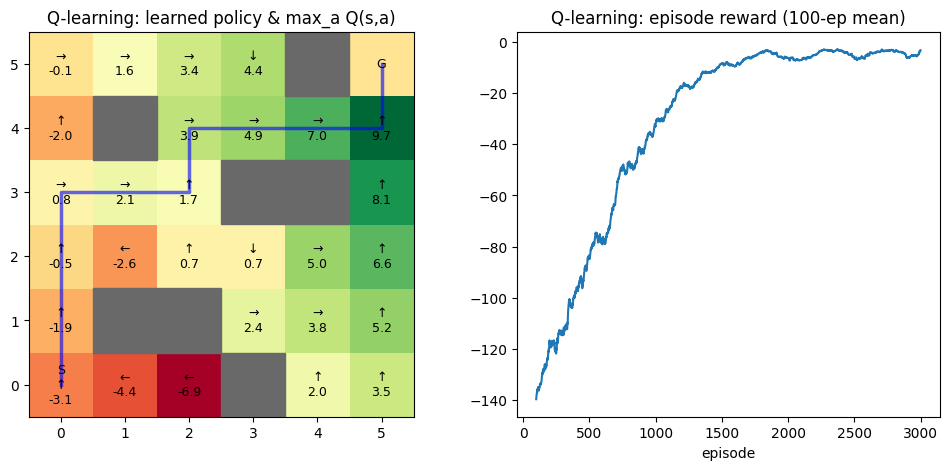

Q-values of the start state: {'↑': np.float64(-3.15), '→': np.float64(-5.24), '↓': np.float64(-4.87), '←': np.float64(-5.47)}


In [ ]:
def q_learning(env, episodes=3000, alpha=0.2, gamma=0.95, eps0=1.0, eps_min=0.05, seed=0):
    rng = np.random.default_rng(seed); env.rng = np.random.default_rng(seed + 100)

    Q = np.zeros((env.nS, 4)); rewards, succ = [], []

    for ep in range(episodes):
        eps = max(eps_min, eps0 * (1 - ep / (0.6 * episodes)))
        s = env.reset(); done, tot = False, 0
        while not done:
            a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))

            s2, r, done, ok = env.step(a)

            target = r + (0 if (done and env.t < env.max_steps) else gamma * Q[s2].max())

            Q[s, a] += alpha * (target - Q[s, a]); s, tot = s2, tot + r

        rewards.append(tot); succ.append(ok)
    return Q, np.array(rewards), np.array(succ)

t0 = time.time(); Q, rew_q, succ_q = q_learning(env); t_q = time.time() - t0

pi_q = Q.argmax(1)
print(f"Q-learning: 3000 episodes in {t_q:.1f}s")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

draw(ax[0], Q.max(1), pi_q, "Q-learning: learned policy & max_a Q(s,a)", greedy_path(pi_q))

ax[1].plot(pd.Series(rew_q).rolling(100).mean()); ax[1].set(title="Q-learning: episode reward (100-ep mean)", xlabel="episode"); plt.show()

print("Q-values of the start state:", dict(zip(ARROWS, Q[env.idx(env.start)].round(2))))


## Part 4 — Deep Q-Network (DQN) in PyTorch

**Deep Q-Network (DQN)** is a model-free, value-based reinforcement learning algorithm that approximates the action-value function using a trainable neural network. Unlike tabular Q-Learning, which stores Q-values in a discrete table, DQN uses a neural network \(Q_\theta(s,\cdot)\) to estimate the Q-values of all available actions from the observed state features.

The network receives **sensor-based state features**, consisting of normalized robot coordinates and four obstacle/boundary indicators:

$$
\boxed{
x(s)=[x_n,y_n,b_1,b_2,b_3,b_4]
}
$$

where \(x_n\) and \(y_n\) represent normalized robot coordinates, and \(b_i\) indicates whether the corresponding neighbouring cell is blocked.

### 4.1 Neural Network Architecture

The neural network approximates the action-value function:

$$
Q_\theta(x,a)\approx Q^*(s,a)
$$

The implemented architecture consists of an input layer, two fully connected hidden layers with 64 neurons each, ReLU activation functions, and an output layer representing the four possible actions.

$$
\boxed{
6 \rightarrow 64 \rightarrow 64 \rightarrow 4
}
$$

The network produces the Q-values for all available actions:

$$
Q_\theta(x,\cdot)=
\begin{bmatrix}
Q_\theta(x,a_1) &
Q_\theta(x,a_2) &
Q_\theta(x,a_3) &
Q_\theta(x,a_4)
\end{bmatrix}
$$

### 4.2 Key DQN Components and Mathematical Formulation

**1. $\varepsilon$-Greedy Exploration:**

The agent balances exploration of unfamiliar actions with exploitation of learned Q-values using an epsilon-greedy strategy:

$$
a_t=
\begin{cases}
\text{Random}(A), & \text{with probability }\varepsilon_t\\
\arg\max_a Q_\theta(x_t,a), & \text{otherwise}
\end{cases}
$$

The exploration probability decreases during training:

$$
\boxed{
\varepsilon_e=
\max\left(
\varepsilon_{\min},
1-\frac{e}{0.6N}
\right)
}
$$

where \(N\) is the total number of training episodes, \(e\) is the current episode, and \(\varepsilon_{\min}=0.05\).

**2. Experience Replay Buffer:**

Past interactions are stored as transition tuples:

$$
\boxed{
\mathcal{B}=
\left\{
(x_t,a_t,r_t,x_{t+1},d_t)
\right\}
}
$$

A random mini-batch of transitions is sampled from the replay buffer:

$$
\mathcal{M}\sim\operatorname{Uniform}(\mathcal{B})
$$

This reduces temporal correlation between consecutive experiences and improves training stability.

**3. Target Network:**

DQN maintains two neural networks:

- **Online network:** \(Q_\theta(x,a)\), which is trained using gradient updates.
- **Target network:** \(Q_{\theta^-}(x,a)\), which provides more stable target estimates.

The target network is periodically synchronized with the online network:

$$
\boxed{
\theta^- \leftarrow \theta
}
$$

In this implementation, synchronization occurs every 200 environment steps.

**4. Bellman Target Calculation:**

The target Q-value is calculated using the immediate reward and maximum estimated future Q-value from the target network:

$$
\boxed{
y_t=
r_t+
\gamma(1-d_t)
\max_{a'}Q_{\theta^-}(x_{t+1},a')
}
$$

where \(d_t=1\) for a genuine terminal transition and \(d_t=0\) otherwise.

**5. Temporal-Difference Error:**

The difference between the predicted Q-value and the Bellman target is:

$$
\boxed{
\delta_t=
y_t-Q_\theta(x_t,a_t)
}
$$

**6. Huber Loss (Smooth L1 Loss):**

The network parameters are optimized by minimizing the Smooth L1 loss:

$$
L(\theta)=
\frac{1}{B}
\sum_{i=1}^{B}
\operatorname{SmoothL1}
\left(
Q_\theta(x_i,a_i)-y_i
\right)
$$

where \(B\) is the mini-batch size.

The Smooth L1 loss is defined as:

$$
\operatorname{SmoothL1}(e)=
\begin{cases}
\frac{1}{2}e^2, & |e|<1\\
|e|-\frac{1}{2}, & |e|\geq1
\end{cases}
$$

It reduces sensitivity to large temporal-difference errors and helps stabilize neural network training.

**7. Neural Network Parameter Optimization:**

The online network parameters are updated using backpropagation and the Adam optimizer:

$$
\boxed{
\theta \leftarrow
\theta-\eta\nabla_\theta L(\theta)
}
$$

where \(\eta\) is the learning rate, set to \(10^{-3}\) in this implementation.

### 4.3 DQN Training Procedure

The overall learning process can be summarized as follows:

1. Initialize the online and target Q-networks with identical parameters.
2. Initialize the experience replay buffer.
3. Reset the environment and extract the initial sensor features.
4. Select an action using the $\varepsilon$-greedy strategy.
5. Execute the action and observe the next state, reward, and termination status.
6. Store the transition in the replay buffer.
7. Randomly sample a mini-batch once the buffer contains sufficient experiences.
8. Calculate target Q-values using the target network and Bellman equation.
9. Calculate the Smooth L1 loss between predicted and target Q-values.
10. Update the online network using backpropagation and Adam optimization.
11. Synchronize the target network every 200 environment steps.
12. Repeat until all training episodes are completed.

### 4.4 Optimal Policy Extraction

After training, the learned greedy policy is extracted by selecting the action with the maximum predicted Q-value:

$$
\boxed{
\pi_\theta(s)=
\arg\max_{a\in A}Q_\theta(x(s),a)
}
$$

The estimated state value is:

$$
V_\theta(s)=
\max_{a\in A}Q_\theta(x(s),a)
$$

**Objective:** Implement a Deep Q-Network agent that learns robot navigation policies directly from sensor-based observations by approximating the optimal action-value function. The agent uses experience replay, a periodically updated target network, epsilon-greedy exploration, and Huber loss to improve learning stability and navigation performance without requiring an explicit transition or reward model.


DQN: 500 episodes in 20.2s


[Text(0.5, 1.0, 'Cumulative reward per episode (50-ep mean)')]

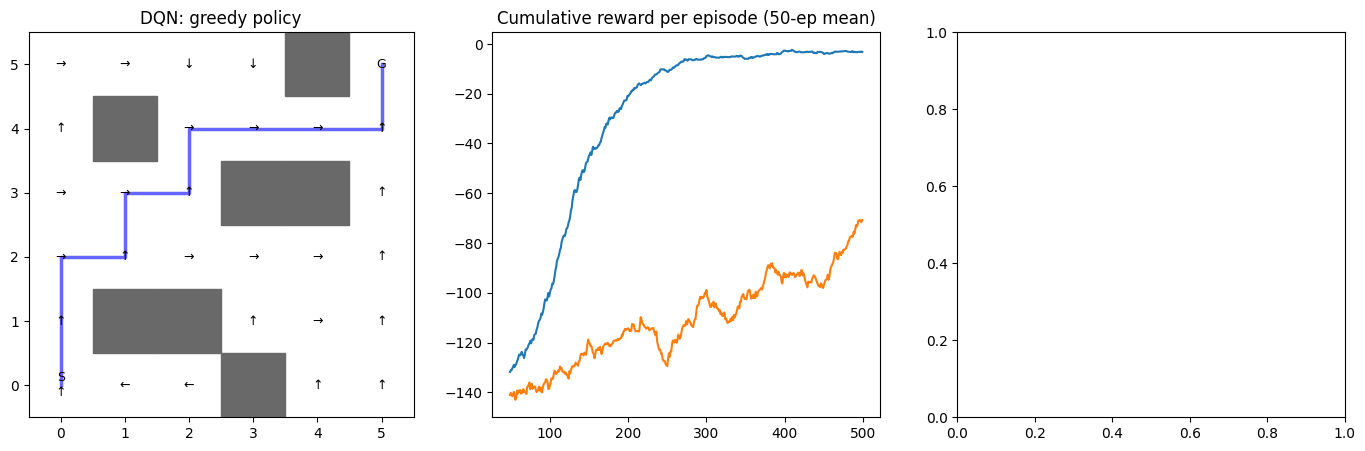

In [ ]:
class QNet(nn.Module):
    def __init__(s, d_in=6, n_a=4, h=64): super().__init__(); s.net = nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, n_a))
    def forward(s, x): return s.net(x)

def dqn(env, episodes=500, gamma=0.95, lr=1e-3, batch=64, buf_size=20000, target_every=200, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); env.rng = np.random.default_rng(seed + 100)

    q, qt = QNet(), QNet(); qt.load_state_dict(q.state_dict()); opt = torch.optim.Adam(q.parameters(), lr)

    buf = deque(maxlen=buf_size); rewards, succ, losses, step = [], [], [], 0

    for ep in range(episodes):
        eps = max(0.05, 1 - ep / (0.6 * episodes)); s = env.reset(); x = env.features(env.p); done, tot = False, 0
        while not done:
            if rng.random() < eps: a = int(rng.integers(4))
            else:
                with torch.no_grad(): a = int(q(torch.tensor(x)).argmax())

            s2, r, done, ok = env.step(a); x2 = env.features(env.p)

            buf.append((x, a, r, x2, float(done and env.t < env.max_steps))); x, tot = x2, tot + r; step += 1

            if len(buf) >= 500:
                bx, ba, br, bx2, bd = map(np.array, zip(*random.sample(buf, batch)))
                bx, bx2 = torch.tensor(bx), torch.tensor(bx2); ba = torch.tensor(ba); br = torch.tensor(br, dtype=torch.float32); bd = torch.tensor(bd, dtype=torch.float32)

                with torch.no_grad(): y = br + gamma * (1 - bd) * qt(bx2).max(1).values

                loss = nn.functional.smooth_l1_loss(q(bx).gather(1, ba[:, None])[:, 0], y)

                opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())

            if step % target_every == 0: qt.load_state_dict(q.state_dict())

        rewards.append(tot); succ.append(ok)
    return q, np.array(rewards), np.array(succ), losses

t0 = time.time(); qnet, rew_d, succ_d, loss_d = dqn(env); t_d = time.time() - t0
print(f"DQN: 500 episodes in {t_d:.1f}s")

dqn_act = lambda s: int(qnet(torch.tensor(env.features(env.pos(s)))).argmax())
with torch.no_grad(): pi_d = np.array([dqn_act(i) for i in range(env.nS)])

fig, ax = plt.subplots(1, 3, figsize=(17, 5))

draw(ax[0], None, pi_d, "DQN: greedy policy", greedy_path(pi_d))

ax[1].plot(pd.Series(rew_d).rolling(50).mean(), label="DQN"); ax[1].plot(pd.Series(rew_q[:500]).rolling(50).mean(), label="Q-learning (first 500 ep)")
ax[1].set(title="Cumulative reward per episode (50-ep mean)")

## Part 5 — Same Environment with Gymnasium + Stable-Baselines3

In practice, wrap the robot navigation simulator as a `gymnasium.Env` environment and use a tested reinforcement learning implementation from Stable-Baselines3.

The Gymnasium environment provides a standardized `reset()` and `step()` API, allowing different reinforcement learning algorithms to interact with the same simulator.

### Key Components

- **Gymnasium:** Defines the environment interface, including observations, actions, rewards, and episode termination.
- **Stable-Baselines3:** Provides a reliable implementation of algorithms such as Deep Q-Network (DQN).
- **Policy evaluation:** Use `evaluate_policy` to calculate the mean episode reward and its standard deviation across multiple evaluation episodes.

**Objective:** Train and evaluate a DQN agent using a standardized library workflow and compare its performance with the custom implementations from previous sections.

In [ ]:
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import DQN as SB3DQN
from stable_baselines3.common.evaluation import evaluate_policy

class GridRobotGym(gym.Env):
    def __init__(s):
        super().__init__()
        s.g = GridRobot(seed=7)
        s.observation_space = spaces.Box(0, 1, (6,), np.float32); s.action_space = spaces.Discrete(4)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed); self.g.reset(); return self.g.features(self.g.p), {}

    def step(s, a):
        _, r, done, ok = s.g.step(int(a))
        trunc = s.g.t >= s.g.max_steps and not ok
        return s.g.features(s.g.p), float(r), bool(done and not trunc), bool(trunc), {"is_success": ok}

genv = GridRobotGym()

genv_ok = None
sb3 = SB3DQN("MlpPolicy", genv, learning_rate=1e-3, buffer_size=20000, learning_starts=500, batch_size=64,
             train_freq=1, gradient_steps=1, exploration_fraction=0.4, exploration_final_eps=0.05,
             target_update_interval=200, gamma=0.95, policy_kwargs=dict(net_arch=[64, 64]), seed=0, verbose=0)

t0 = time.time(); sb3.learn(total_timesteps=25000); t_sb3 = time.time() - t0

m_sb3, s_sb3 = evaluate_policy(sb3, genv, n_eval_episodes=100)
print(f"SB3 DQN trained in {t_sb3:.1f}s → mean reward {m_sb3:.2f} ± {s_sb3:.2f}")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


SB3 DQN trained in 60.1s → mean reward -2.11 ± 5.47



## Part 6 — Evaluation and Comparison

The performance of all reinforcement learning and Dynamic Programming methods is evaluated using a common stochastic robot navigation environment. Each final learned policy is evaluated over **200 independent episodes** with a slip probability of \(p_{\text{slip}}=0.1\).

The evaluation uses greedy action selection for learned policies, without additional exploratory actions. The random policy is included as an untrained baseline for comparison.

### 6.1 Evaluation Protocol

The following methods are considered:

- **Random Policy:** Baseline performance before training.
- **Value Iteration (DP):** Greedy policy extracted from the optimal state-value function.
- **Policy Iteration (DP):** Greedy policy obtained through policy evaluation and improvement.
- **Q-Learning:** Tabular Q-Learning evaluated using three independently trained policies.
- **Custom DQN:** PyTorch-based DQN evaluated using three independently trained networks.
- **Stable-Baselines3 DQN:** Framework-based DQN evaluated using deterministic action selection.

For each evaluation episode, the robot starts from its initial position and interacts with the stochastic environment until reaching the goal or the maximum episode length.

### 6.2 Evaluation Metrics

**1. Mean Episode Reward**

The cumulative reward obtained during evaluation episode \(i\) is:

$$
G_i=\sum_{t=0}^{T_i-1}r_{i,t}
$$

The mean episode reward over \(N_{\text{eval}}=200\) episodes is:

$$
\boxed{
\bar{R}=
\frac{1}{N_{\text{eval}}}
\sum_{i=1}^{N_{\text{eval}}}G_i
}
$$

**Objective:** Measure the average cumulative reward obtained by the robot during navigation. Higher mean rewards generally indicate better navigation performance.

**2. Success Rate**

A binary success indicator is defined as:

$$
S_i=
\begin{cases}
1, & \text{if the robot reaches the goal}\\
0, & \text{otherwise}
\end{cases}
$$

The success rate is calculated as:

$$
\boxed{
SR=
\frac{1}{N_{\text{eval}}}
\sum_{i=1}^{N_{\text{eval}}}S_i
}
$$

Alternatively, expressed as a percentage:

$$
SR(\%)=
\frac{\sum_{i=1}^{N_{\text{eval}}}S_i}
{N_{\text{eval}}}\times100
$$

**Objective:** Quantify the reliability of each navigation policy in reaching the target under stochastic environmental conditions.

**3. Mean Successful Path Length**

Let \(L_i\) represent the number of steps taken during evaluation episode \(i\). The mean path length is calculated only over successful episodes:

$$
\boxed{
\bar{L}=
\frac{
\sum_{i=1}^{N_{\text{eval}}}S_iL_i
}{
\sum_{i=1}^{N_{\text{eval}}}S_i
}
}
$$

**Objective:** Measure the average number of navigation steps required to reach the goal. Lower values indicate more efficient navigation.

**4. Mean Collision Frequency**

Let \(C_i\) represent the number of collisions encountered during evaluation episode \(i\).

$$
\boxed{
\bar{C}=
\frac{1}{N_{\text{eval}}}
\sum_{i=1}^{N_{\text{eval}}}C_i
}
$$

**Objective:** Evaluate the collision avoidance capability and safety performance of each navigation policy.

**5. Training Time**

Let \(t_j\) represent the computational training time of the algorithm under training run \(j\).

For learning-based methods evaluated over three random seeds:

$$
\boxed{
\bar{T}_{\text{train}}=
\frac{1}{3}\sum_{j=1}^{3}t_j
}
$$

**Objective:** Assess the computational efficiency and training requirements of each algorithm.

### 6.3 Multi-Seed Experimental Evaluation

To investigate the consistency and robustness of learning-based methods, Q-Learning and custom DQN are trained independently using three random seeds:

$$
\mathcal{S}=\{0,1,2\}
$$

For each training seed, the resulting greedy policy is evaluated over 200 stochastic episodes.

The mean performance across the three independent training runs is calculated as:

$$
\boxed{
\mu_M=
\frac{1}{3}\sum_{j=1}^{3}M_j
}
$$

The corresponding population standard deviation is:

$$
\boxed{
\sigma_M=
\sqrt{
\frac{1}{3}
\sum_{j=1}^{3}(M_j-\mu_M)^2
}
}
$$

where \(M_j\) represents an evaluation metric obtained from training run \(j\).

The experimental results are reported as:

$$
\boxed{\text{Performance}=\mu_M\pm\sigma_M}
$$

**Objective:** Quantify the variability of learning performance across independent training runs and assess the consistency of the learned navigation policies.

### 6.4 Experimental Procedure

1. Initialize the comparison results table.
2. Evaluate the random navigation policy as an untrained baseline.
3. Evaluate the optimal policies obtained from Value Iteration and Policy Iteration.
4. Train Q-Learning independently using three random seeds.
5. Extract the greedy Q-Learning policy using:

   $$
   \pi_Q(s)=\arg\max_{a\in A}Q(s,a)
   $$

6. Train the custom PyTorch DQN independently using three random seeds.
7. Extract the greedy DQN policy using:

   $$
   \pi_{\theta}(s)=
   \arg\max_{a\in A}Q_{\theta}(x(s),a)
   $$

8. Evaluate each trained policy over 200 stochastic episodes without exploratory actions.
9. Evaluate the Stable-Baselines3 DQN using deterministic action selection.
10. Calculate mean and standard deviation for the three independent Q-Learning and custom DQN runs.
11. Compile all evaluation metrics into a comparative results table.
12. Export the results as a CSV file.
13. Generate a success-rate comparison plot.

### 6.5 Comparative Results and Visualization

The final comparison considers the following performance indicators:

| Metric | Evaluation objective | Preferred outcome |
|---|---|---|
| Mean reward | Cumulative navigation performance | Higher |
| Success rate | Goal-reaching reliability | Higher |
| Mean path length | Navigation efficiency | Lower |
| Collisions per episode | Collision avoidance | Lower |
| Training time | Computational efficiency | Lower |

The experimental results are organized into a comparative table containing the performance of each algorithm.

$$
\text{Results}=
\begin{bmatrix}
\text{Method} &
\bar{R} &
SR &
\bar{L} &
\bar{C} &
\bar{T}_{\text{train}}
\end{bmatrix}
$$

The results are saved in:

`data/rl_comparison_results.csv`

A horizontal bar chart is also generated to compare the success rates of the different navigation methods.

**Objective:** Compare the learning performance, navigation reliability, collision avoidance, computational efficiency and robustness of model-based Dynamic Programming and model-free reinforcement learning algorithms on a common stochastic robot navigation task.


,method,mean reward,success rate,path length,collisions / ep,train time s
0,Random policy (before training),-135.550,0.025,34.200,9.580,0.000
1,Value iteration (DP),-1.320,1.000,10.970,0.150,0.031
2,Policy iteration (DP),-1.320,1.000,10.970,0.150,NaN
3,Q-learning (3 seeds),-2.077,1.000,11.247,0.203,0.640
4,± std,0.180,0.000,0.058,0.025,NaN
5,DQN (ours) (3 seeds),-2.132,1.000,11.167,0.218,17.947
6,± std,0.208,0.000,0.040,0.022,NaN
7,SB3 DQN,-1.455,1.000,11.060,0.155,60.074


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


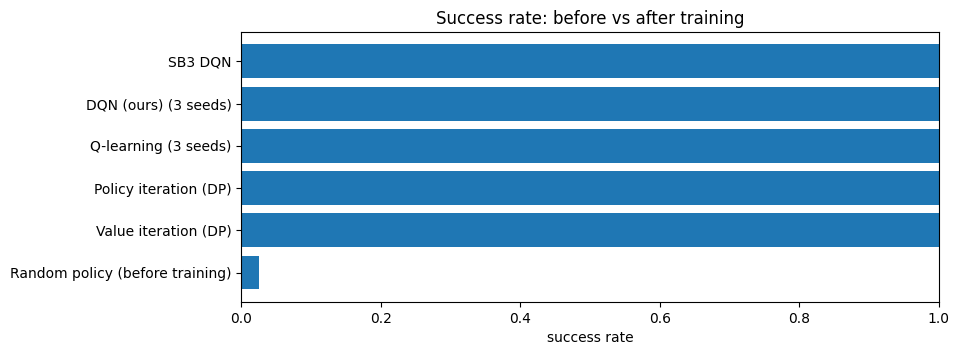

In [ ]:
rand_act = lambda s: np.random.randint(4)

rows = [["Random policy (before training)", *rollout(env, rand_act), 0],
        ["Value iteration (DP)", *rollout(env, lambda s: pi_vi[s]), t_vi],
        ["Policy iteration (DP)", *rollout(env, lambda s: pi_pi[s]), np.nan]]

for name, fn in [("Q-learning", lambda sd: q_learning(GridRobot(), seed=sd)[0].argmax(1)),
                 ("DQN (ours)", lambda sd: dqn(GridRobot(), seed=sd)[0])]:
    res = []
    for sd in range(3):
        t0 = time.time(); pol = fn(sd); tt = time.time() - t0

        if isinstance(pol, nn.Module):
            with torch.no_grad(): act = (lambda p_: (lambda s: int(p_(torch.tensor(env.features(env.pos(s)))).argmax())))(pol)
        else: act = (lambda p_: (lambda s: p_[s]))(pol)

        res.append([*rollout(env, act, seed=10 + sd), tt])

    res = np.array(res); rows.append([f"{name} (3 seeds)", *res[:, :4].mean(0), res[:, 4].mean()]); rows.append([f"   ± std", *res[:, :4].std(0), np.nan])

rows.append(["SB3 DQN", *rollout(env, lambda s: int(sb3.predict(env.features(env.pos(s)), deterministic=True)[0])), t_sb3])

cmp = pd.DataFrame(rows, columns=["method", "mean reward", "success rate", "path length", "collisions / ep", "train time s"])
display(cmp.round(3))

cmp.to_csv(DATA / "rl_comparison_results.csv", index=False)

sr = cmp[~cmp.method.str.contains("±")]
plt.figure(figsize=(9, 3.5)); plt.barh(sr.method, sr["success rate"], color="tab:blue"); plt.xlabel("success rate"); plt.title("Success rate: before vs after training"); plt.xlim(0, 1); plt.show()

## Conclusions

### Comparison of Reinforcement Learning Methods

| Feature | Dynamic Programming | Q-Learning | Deep Q-Network (DQN) |
|---|---|---|---|
| Requires transition model $P(s' \mid s,a)$? | **Yes** | No | No |
| State space | Small, discrete | Small, discrete (Q-table) | Large or continuous (neural network) |
| Sample efficiency | No interaction samples required when the model is known | Typically requires many episodes | Requires experience replay and a target network for improved stability |
| Optimality guarantee | Optimal for a correctly specified model when solved appropriately | Converges under suitable learning conditions | No general convergence guarantee; sensitive to random seeds and hyperparameters |

### Key Takeaways

- **Dynamic programming (DP)** provides an optimal reference policy when the environment model is known and the algorithm converges correctly. Model-free methods learn policies through experience and may approach the DP solution.
- **Evaluate reinforcement learning with multiple random seeds.** Report mean reward, success rate, path length, and constraint violations such as collisions, rather than relying on a single reward curve.
- **Follow a systematic robotics workflow:** Build the environment in a grid world or Gazebo → define states, actions, and rewards → train in simulation → evaluate performance → transfer to the physical robot with appropriate safety checks.
- **Physical deployment requires validation.** Account for sensor noise, wheel slip, actuator limitations, and environmental differences before deploying a learned policy on a real robot. Notebook 16 introduces the TurtleBot3 ROS 2 implementation.

### Exercises

1. **Increase transition uncertainty:** Set `slip = 0.3` and investigate how the optimal policy changes to reduce collision risk.
2. **Introduce obstacle proximity costs:** Add a reward penalty of `-0.5` for occupying a cell adjacent to an obstacle. Compare the resulting navigation policy.
3. **Experiment with PPO:** Train a Proximal Policy Optimization (PPO) agent using Stable-Baselines3 and compare its performance with DQN.
4. **Analyze robustness:** Evaluate each learned policy across multiple random seeds and compare success rates, path lengths, cumulative rewards, and collision counts.

**Final objective:** Understand the trade-offs between model-based planning and model-free reinforcement learning, and apply these methods to safe, reliable robot navigation.